In [2]:
from astropy.io import fits
import pandas as pd
import numpy as np


Reading the APOGEE DR17 data 

In [3]:
from astropy.table import Table
dat = Table.read('allStar-dr17-synspec_rev1.fits', format='fits')
names = [name for name in dat.colnames if len(dat[name].shape) <= 1]
allstar = dat[names].to_pandas()

In [4]:
allstar.columns.values

array(['FILE', 'APOGEE_ID', 'TARGET_ID', 'APSTAR_ID', 'ASPCAP_ID',
       'TELESCOPE', 'LOCATION_ID', 'FIELD', 'ALT_ID', 'RA', 'DEC', 'GLON',
       'GLAT', 'J', 'J_ERR', 'H', 'H_ERR', 'K', 'K_ERR', 'SRC_H',
       'WASH_M', 'WASH_M_ERR', 'WASH_T2', 'WASH_T2_ERR', 'DDO51',
       'DDO51_ERR', 'IRAC_3_6', 'IRAC_3_6_ERR', 'IRAC_4_5',
       'IRAC_4_5_ERR', 'IRAC_5_8', 'IRAC_5_8_ERR', 'IRAC_8_0',
       'IRAC_8_0_ERR', 'WISE_4_5', 'WISE_4_5_ERR', 'TARG_4_5',
       'TARG_4_5_ERR', 'WASH_DDO51_GIANT_FLAG', 'WASH_DDO51_STAR_FLAG',
       'TARG_PMRA', 'TARG_PMDEC', 'TARG_PM_SRC', 'AK_TARG',
       'AK_TARG_METHOD', 'AK_WISE', 'SFD_EBV', 'APOGEE_TARGET1',
       'APOGEE_TARGET2', 'APOGEE2_TARGET1', 'APOGEE2_TARGET2',
       'APOGEE2_TARGET3', 'APOGEE2_TARGET4', 'TARGFLAGS', 'SURVEY',
       'PROGRAMNAME', 'NVISITS', 'SNR', 'SNREV', 'STARFLAG', 'STARFLAGS',
       'ANDFLAG', 'ANDFLAGS', 'VHELIO_AVG', 'VSCATTER', 'VERR', 'RV_TEFF',
       'RV_LOGG', 'RV_FEH', 'RV_ALPHA', 'RV_CARB', 'RV_CHI2', '

and adding the distances from Bailer Jones

In [5]:
#BJ distances
pd.set_option('display.max_seq_items', 500)
# Read the data
BJ_distances_hdus = fits.open('apogee_BJ_distances.fits')
BJ_distances = pd.DataFrame(BJ_distances_hdus[1].data)
BJ_distances_hdus.close()


print ((BJ_distances.columns))


FileNotFoundError: [Errno 2] No such file or directory: 'apogee_BJ_distances.fits'

In [5]:
#apogee_BJdistances= allstar.merge(BJ_distances, left_on = 'GAIAEDR3_SOURCE_ID', right_on = 'gaiaedr3_source_id')
#print (len(apogee_BJdistances))

### Excluding bad measurements based on some flags

In [11]:
#APOGEE_STARFLAG
# PERSIST_HIGH	(bit = 9)	Spectrum has significant number (>20%) of pixels in high persistence region: WARN
allstar = allstar[allstar['STARFLAG'] != 2**9]
print (len(allstar))
# LOW_SNR	(bit = 4)	Spectrum has low S/N (S/N<5)
allstar = allstar[allstar['STARFLAG'] != 2**4]
#VERY_BRIGHT_NEIGHBOR	(bit = 3)	Star has neighbor more than 100 times brighter: possibly BAD
allstar = allstar[allstar['STARFLAG'] != 2**3]
#PERSIST_JUMP_POS	(bit = 12)	Spectrum show obvious positive jump in blue chip: WARN
allstar = allstar[allstar['STARFLAG'] != 2**12]
#PERSIST_JUMP_NEG	(bit = 13)	Spectrum show obvious negative jump in blue chip: WARN
allstar = allstar[allstar['STARFLAG'] != 2**13]
#SUSPECT_RV_COMBINATION	(bit = 16)	RVs from synthetic template differ significantly (~2 km/s) from those from combined template: WARN
allstar = allstar[allstar['STARFLAG'] != 2**16]


#APOGEE_EXTRATARG
# Select stars from the Main Survey Targets: no information in the bitmaks
MST = allstar[allstar['EXTRATARG'] == 0]
print (len(MST))



700193
351883


### Further selection

https://www.sdss4.org/dr17/irspec/abundances/

cool (Teff < 3500) and hot (Teff > 6000) stars are not good.
SNR > 100 should be considered

In [1]:
criteria = (MST['TEFF'] > 3500) & (MST['TEFF'] < 6000) & (MST['SNR'] > 100)
MST = MST[criteria]
print (len(MST))

NameError: name 'MST' is not defined

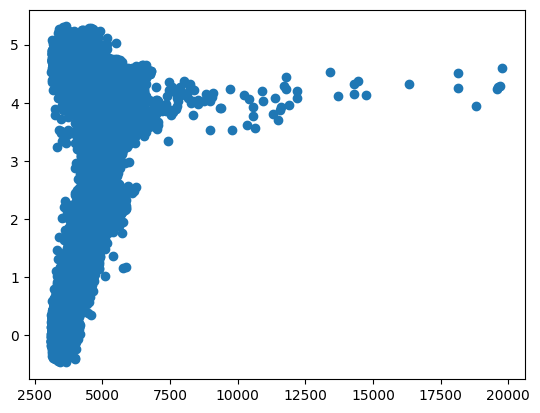

In [15]:
import matplotlib.pyplot as plt
plt.scatter(MST.TEFF, MST.LOGG)

In [12]:
MST['TEFF'].describe()

count    343806.000000
mean       4724.820801
std         612.441711
min        3107.097168
25%        4316.025879
50%        4736.763672
75%        5020.237793
max       19773.939453
Name: TEFF, dtype: float64

In [7]:
print (len(allstar))

700193


Selecting RGB stars with high precision abundances and high SNR

In [7]:
#Selecting Red Giant stars with 1 < logg < 3; 4000 < Teff < 5500; -1 < [Fe/H] < 0.6
MRS_sample = MRS[(MRS['LOGG'] <3) & (MRS['LOGG'] > 0) & (MRS['TEFF'] > 4000) & (MRS['TEFF'] < 5500) & (MRS['FE_H'] > -1) & (MRS['FE_H'] < 0.6)]
print (f'MRS sample size: {len(MRS_sample)}')


#Selecting good quality RGB stars
MRS_good = MRS_sample[(MRS_sample['TEFF_ERR'] < 20) & (MRS_sample['LOGG_ERR'] < 0.04) & (MRS_sample['FE_H_ERR'] < 0.02) & (MRS_sample['SNR'] > 500)]

MRS_good.to_csv('MRS_good.csv', index = False)


print (f'MRS good sample size: {len(MRS_good)}')

MRS sample size: 159579
MRS good sample size: 14056


In [8]:
#Selecting best quality RGB stars
MRS_clean = MRS_good[(MRS_good['MG_FE'] > -0.1) & (MRS_good['MG_FE'] < 0.4) & (MRS_good['SI_FE'] > -0.06) & (MRS_good['SI_FE'] < 0.3) & (MRS_good['C_FE'] > -0.3) & (MRS_good['C_FE'] < 0.25) & (MRS_good['O_FE'] > -0.1) & (MRS_good['O_FE'] < 0.55)]

print (len(MRS_clean))

13902


# Use Gaussian Mixture to separate the thin/thick disk populations

/tmp/ipykernel_26556/2680783392.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['mg_fe_offset'] = df['MG_FE']  + 0.15*df['FE_H'] - 0.125
/tmp/ipykernel_26556/2680783392.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['popul'] = df['mg_fe_offset'].apply(lambda x: 'thin' if x < 0 else 'thick')


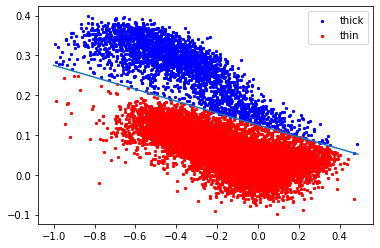

In [9]:
def thin_thick(df):
    df['mg_fe_offset'] = df['MG_FE']  + 0.15*df['FE_H'] - 0.125
    df['popul'] = df['mg_fe_offset'].apply(lambda x: 'thin' if x < 0 else 'thick')

    thick = df[df['popul'] == 'thick']
    thin = df[df['popul'] == 'thin']

    return df, thick, thin

disk, thick, thin = thin_thick(MRS_clean)

import matplotlib.pyplot as plt

x = np.array(np.arange(-1,0.5,0.01))
y = -0.15*x + 0.125
plt.scatter(thick['FE_H'], thick['MG_FE'], s = 5, c = 'blue', label = 'thick')
plt.scatter(thin['FE_H'], thin['MG_FE'], s = 5, c = 'red', label = 'thin')
plt.plot(x, y)
plt.legend()
plt.show()

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.mixture import GaussianMixture


def el_fe(elem):
    X = MRS_clean[['%s_FE' % elem, 'FE_H']]
    gm = GaussianMixture(n_components=2).fit(X)
    MRS_clean['class'] = gm.predict(X)

    MRS_clean_thin = MRS_clean[MRS_clean['class'] == 1]
    MRS_clean_thick = MRS_clean[MRS_clean['class'] == 0]

    x = np.array(np.arange(-1,0.5,0.01))
    y = -0.15*x + 0.135

    plt.scatter(MRS_clean_thin['FE_H'], MRS_clean_thin['MG_FE'], s = 5)
    plt.scatter(MRS_clean_thick['FE_H'], MRS_clean_thick['MG_FE'], s = 5)
    plt.plot(x, y)
    plt.show()

    return MRS_clean_thin, MRS_clean_thick


In [11]:


def estimate_abund_new(elem, feh, feh_err_low, feh_err_high, popul):

    disk, thick, thin = thin_thick(MRS_clean)

    n = 1000
    if popul == 'disk':

        elem_dist_df = pd.DataFrame(index = np.arange(n), columns = ['fe_h', 'elem_h'])

        for i in range(n):

            feh_err_mean = np.abs(feh_err_high + feh_err_low)/2
            feh_tmp = np.random.normal(feh,feh_err_mean,1)

            df_closest_feh = disk.iloc[(disk['FE_H']-feh_tmp).abs().argsort()[:1]]

            elem_dist_df['fe_h'][i] = feh_tmp[0]
            elem_h = df_closest_feh['%s_FE' % elem].values + df_closest_feh['FE_H'].values
            elem_dist_df['elem_h'][i] = elem_h[0]


    if popul == 'thick':

        elem_dist_df = pd.DataFrame(index = np.arange(n), columns = ['fe_h', 'elem_h'])

        for i in range(n):

            feh_err_mean = np.abs(feh_err_high + feh_err_low)/2
            feh_tmp = np.random.normal(feh,feh_err_mean,1)

            df_closest_feh = thick.iloc[(thick['FE_H']-feh_tmp).abs().argsort()[:1]]

            elem_dist_df['fe_h'][i] = feh_tmp[0]
            elem_h = df_closest_feh['%s_FE' % elem].values + df_closest_feh['FE_H'].values
            elem_dist_df['elem_h'][i] = elem_h[0]

    if popul == 'thin':

        elem_dist_df = pd.DataFrame(index = np.arange(n), columns = ['fe_h', 'elem_h'])

        for i in range(n):

            feh_err_mean = np.abs(feh_err_high + feh_err_low)/2
            feh_tmp = np.random.normal(feh,feh_err_mean,1)

            df_closest_feh = thin.iloc[(thin['FE_H']-feh_tmp).abs().argsort()[:1]]

            elem_dist_df['fe_h'][i] = feh_tmp[0]
            elem_h = df_closest_feh['%s_FE' % elem].values + df_closest_feh['FE_H'].values
            elem_dist_df['elem_h'][i] = elem_h[0] 
    
    
    print (np.mean(elem_dist_df['elem_h']))
    print (np.std(elem_dist_df['elem_h']))


In [20]:
estimate_abund_new('MG', -0.11, 0.09, 0.09, 'thick')

/tmp/ipykernel_26556/2680783392.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['mg_fe_offset'] = df['MG_FE']  + 0.15*df['FE_H'] - 0.125
/tmp/ipykernel_26556/2680783392.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['popul'] = df['mg_fe_offset'].apply(lambda x: 'thin' if x < 0 else 'thick')


0.08727219390869141
0.06853977641913472


/tmp/ipykernel_26556/3387817599.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  MRS_clean['class'] = gm.predict(X)


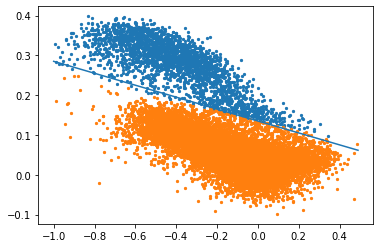

-0.0532143 0.07034083


(-0.0532143, 0.07034083)

In [13]:
def estimate_abund(elem, feh, feh_err_low, feh_err_high, popul):
    thin, thick = el_fe(elem)

    if popul == 'thin':
        sample = thin[(thin['FE_H'] > feh - feh_err_low) & (thin['FE_H'] < feh + feh_err_high)]
        elem_mean = np.mean(sample['%s_FE' % elem] + sample['FE_H'])
        elem_std = np.std(sample['%s_FE' % elem] + sample['FE_H'])
    elif popul == 'thick':
        sample = thick[(thick['FE_H'] > feh - feh_err_low) & (thick['FE_H'] < feh + feh_err_high)]
        elem_mean = np.mean(sample['%s_FE' % elem] + sample['FE_H'])
        elem_std = np.std(sample['%s_FE' % elem] + sample['FE_H'])
    elif popul == 'disk':
        sample = MRS_clean[(MRS_clean['FE_H'] > feh - feh_err_low) & (MRS_clean['FE_H'] < feh + feh_err_high)]
        elem_mean = np.mean(sample['%s_FE' % elem] + sample['FE_H'])
        elem_std = np.std(sample['%s_FE' % elem] + sample['FE_H'])        

        
    print (elem_mean, elem_std)   
    return elem_mean, elem_std
    
estimate_abund('MG', -0.11, 0.09, 0.09, 'disk')